# Capstone — mirrors your deployed research paper

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/saibalaji2004/Flyrank-intern-repo/blob/main/work/notebooks/capstone.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

## 1. Question

*The research question and the decision it supports.*

### Research question

Why do some web pages experience declining search performance, and how can content teams identify which pages should be reviewed first for potential content improvements?

### Decision supported

The study supports a practical decision: which pages should a content strategist or SEO team review first, and what signals explain their priority?

### Objective

Compare a transparent, rule-based baseline with a Logistic Regression model to evaluate whether available page characteristics can help prioritize pages for human review.

### Intended audience

Content strategists and SEO teams responsible for maintaining and improving existing web content.

### Scope

The analysis uses an anonymized dataset and an observed decline label derived from `trend_direction`. It investigates whether the available signals are useful for review prioritization. It does not establish why a page declined, prove that refreshing a page will improve its performance, or guarantee future search results.

In [ ]:

research_question = (
    "Why do some web pages experience declining search performance, "
    "and how can content teams identify which pages should be "
    "reviewed first for potential content improvements?"
)

decision_supported = (
    "Prioritize web pages for human review using explainable signals."
)

assert research_question.strip()
assert decision_supported.strip()

print("Research question:", research_question)
print("Decision supported:", decision_supported)
print("\nPASS: research question and decision are defined.")


Research question: Why do some web pages experience declining search performance, and how can content teams identify which pages should be reviewed first for potential content improvements?
Decision supported: Prioritize web pages for human review using explainable signals.

PASS: research question and decision are defined.


## 2. Data

*Which release, which tables, date windows, what you excluded and why. Public-safe.*

### Dataset and scope

This study uses the anonymized FlyRank content-refresh starter dataset, containing 30,000 rows and 44 original columns. Each row represents a content record identified by a pseudonymous content ID. The dataset includes page characteristics, search-demand attributes, engagement metrics, freshness information, and performance trends.

### Target label

The binary target `is_declining_label` is derived from `trend_direction`: rows with `trend_direction == "down"` are labelled 1, and all other trend categories are labelled 0. This label is an observed trend proxy, not independent confirmation that a page needs refreshing.

### Data quality and exclusions

The initial dataset contains missing values in several fields, including provider/model metadata and some content characteristics. Missing values should be handled through training-fitted preprocessing rather than indiscriminately replaced with zero. Identifier fields are excluded from predictive features, while `client_id` is retained only for grouped validation.

The six fields comparing the latest 30 days with the previous 30 days are excluded from the model's feature set to reduce the risk of directly revealing information related to the target. `trend_direction`, `trend_pct`, and the derived target are also excluded from predictive inputs.

### Time-window limitations and privacy

The available metrics include 90-day aggregates and comparisons between recent 30-day windows, but the dataset does not provide a complete calendar-dated, point-in-time history for a robust future-period evaluation. Public outputs therefore use aggregate summaries and omit content IDs, client IDs, private URLs, and search queries.

In [ ]:

import pandas as pd

dataset_url = (
    "https://raw.githubusercontent.com/"
    "saibalaji2004/Flyrank-intern-repo/main/"
    "data/raw/content_refresh_anonymized.csv"
)

df = pd.read_csv(dataset_url)

# Derive the observed decline label.
df["is_declining_label"] = (
    df["trend_direction"].eq("down").astype(int)
)

print("Dataset shape:", df.shape)
print("Unique content IDs:", df["content_id"].nunique())
print("Duplicate rows:", int(df.duplicated().sum()))
print("Missing values in selected fields:")

fields_to_check = [
    "provider_used",
    "word_count",
    "char_count",
    "model_used",
    "trend_pct",
    "trend_direction",
]

print(df[fields_to_check].isna().sum().to_string())

assert len(df) == 30000
assert df["content_id"].is_unique
assert df["is_declining_label"].equals(
    df["trend_direction"].eq("down").astype(int)
)

print("\nPASS: dataset and target-label checks completed.")


Dataset shape: (30000, 45)
Unique content IDs: 30000
Duplicate rows: 0
Missing values in selected fields:
provider_used      21438
word_count          7699
char_count          7699
model_used          5733
trend_pct           3388
trend_direction        0

PASS: dataset and target-label checks completed.


## 3. Methodology

*Assumptions, features, label definition, baseline, validation design, leakage checks.*

### Methodology

**Target definition.** The binary target is `is_declining_label`, set to 1 when `trend_direction == "down"` and 0 otherwise. Because the target is derived from an observed trend category, it represents an observed decline proxy rather than a confirmed need for content refresh.

**Rule-based baseline.** The Week-4 baseline assigns two points when a page has not been updated for at least 90 days and one point when its 90-day impressions meet or exceed the median positive impression count, which is 731. Scores map to four actions: `REVIEW_CONTENT` (3), `REVIEW_STALENESS` (2), `REVIEW_VISIBILITY` (1), and `MONITOR` (0).

**Machine-learning model.** Logistic Regression was evaluated using numeric and categorical features. Identifier fields, target-derived trend fields, and six latest-versus-previous 30-day comparison fields were excluded from predictive inputs. Numeric and categorical preprocessing was fitted on training data only.

**Validation design.** A reproducible 80/20 client-grouped split with random seed 42 was used. Training contained 23,837 rows from 25 clients, and testing contained 6,163 rows from seven different clients. This avoids placing the same client in both partitions, but it is not a future-period evaluation.

**Evaluation.** Precision@10 and Precision@20 measure the proportion of declining-label pages among the top-ranked pages. Average precision and ROC-AUC assess broader ranking and discrimination performance. The baseline and model are compared on the same held-out test split.

**Leakage checks.** The model excludes `content_id`, `client_id`, `trend_direction`, `trend_pct`, the target, and the six recent-versus-previous 30-day comparison fields. The checks found no overlap between training and testing clients. Residual temporal leakage cannot be ruled out because a complete point-in-time feature history is unavailable.

In [ ]:

from sklearn.model_selection import GroupShuffleSplit

TARGET = "is_declining_label"
GROUP = "client_id"
RANDOM_STATE = 42

model_df = df.dropna(subset=[GROUP, TARGET]).copy()

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

train_idx, test_idx = next(
    splitter.split(
        model_df,
        y=model_df[TARGET],
        groups=model_df[GROUP],
    )
)

train_df = model_df.iloc[train_idx].copy()
test_df = model_df.iloc[test_idx].copy()

forbidden_features = {
    "content_id",
    "client_id",
    "trend_direction",
    "trend_pct",
    "is_declining_label",
    "impressions_last_30d",
    "clicks_last_30d",
    "sessions_last_30d",
    "impressions_prev_30d",
    "clicks_prev_30d",
    "sessions_prev_30d",
}

# Reproduce the declared feature exclusions.
audit_features = [
    col for col in model_df.columns
    if col not in forbidden_features
]

overlap = (
    set(train_df["client_id"])
    & set(test_df["client_id"])
)

print("Training rows:", len(train_df))
print("Training clients:", train_df["client_id"].nunique())
print("Testing rows:", len(test_df))
print("Testing clients:", test_df["client_id"].nunique())
print("Training decline rate:", round(train_df[TARGET].mean(), 4))
print("Testing decline rate:", round(test_df[TARGET].mean(), 4))
print("Candidate feature count:", len(audit_features))
print("Forbidden fields in features:",
      sorted(set(audit_features) & forbidden_features))
print("Overlapping clients:", len(overlap))

assert len(train_df) == 23837
assert len(test_df) == 6163
assert len(overlap) == 0
assert not (set(audit_features) & forbidden_features)

print("\nPASS: grouped split and explicit exclusion checks completed.")


Training rows: 23837
Training clients: 25
Testing rows: 6163
Testing clients: 7
Training decline rate: 0.5501
Testing decline rate: 0.511
Candidate feature count: 34
Forbidden fields in features: []
Overlapping clients: 0

PASS: grouped split and explicit exclusion checks completed.


## 4. Results (vs baseline)

*Model vs baseline on the same split. The honest table.*

### Results

The Logistic Regression model outperformed the rule-based baseline on Precision@10 and Precision@20 using the same client-grouped held-out test split.

| Metric | Week-4 rule-based baseline | Logistic Regression |
|---|---:|---:|
| Precision@10 | 0.40 | 0.60 |
| Precision@20 | 0.40 | 0.65 |
| Average precision | Not recorded here | 0.564 |
| ROC-AUC | Not recorded here | 0.573 |

At the top 10 positions, the model identified six pages with the observed decline label, compared with four for the baseline. At the top 20 positions, it identified 13, compared with eight for the baseline. These counts describe agreement with the observed label, not confirmed content-refresh opportunities.

The model's ROC-AUC of approximately 0.573 indicates limited overall discrimination. Although its top-ranked results were better on this test split, this does not establish strong predictive ability or guarantee performance on future data. The results support further investigation of model-assisted review prioritization, with human judgment retained as the final decision-maker.

In [ ]:
import numpy as np
import pandas as pd
# Section 4: same held-out split comparison

results = pd.DataFrame([
    {
        "model": "Week-4 rule-based baseline",
        "precision_at_10": 0.40,
        "precision_at_20": 0.40,
        "average_precision": np.nan,
        "roc_auc": np.nan,
    },
    {
        "model": "Logistic Regression",
        "precision_at_10": 0.60,
        "precision_at_20": 0.65,
        "average_precision": 0.564,
        "roc_auc": 0.5726,
    },
])

print(results.to_string(index=False))

baseline = results.loc[
    results["model"] == "Week-4 rule-based baseline"
].iloc[0]
model = results.loc[
    results["model"] == "Logistic Regression"
].iloc[0]

print("\nPrecision@10 improvement:",
      round(model["precision_at_10"] - baseline["precision_at_10"], 2))
print("Precision@20 improvement:",
      round(model["precision_at_20"] - baseline["precision_at_20"], 2))

assert model["precision_at_10"] > baseline["precision_at_10"]
assert model["precision_at_20"] > baseline["precision_at_20"]
assert 0 <= model["roc_auc"] <= 1

print("\nPASS: reported held-out metrics are internally consistent.")
print("Note: values are recorded from ML-08/ML-09, not recomputed here.")


                     model  precision_at_10  precision_at_20  average_precision  roc_auc
Week-4 rule-based baseline              0.4             0.40                NaN      NaN
       Logistic Regression              0.6             0.65              0.564   0.5726

Precision@10 improvement: 0.2
Precision@20 improvement: 0.25

PASS: reported held-out metrics are internally consistent.
Note: values are recorded from ML-08/ML-09, not recomputed here.


## 5. Limitations

*What this work cannot claim.*

### Limitations

This study has several limitations.

1. **Proxy target:** The decline label is derived from `trend_direction`. It does not independently confirm that a page needs a content refresh.
2. **Limited discrimination:** Logistic Regression achieved a ROC-AUC of 0.573 and average precision of 0.564. Better Precision@10 and Precision@20 do not imply strong overall predictive performance.
3. **No future-period validation:** The client-grouped split prevents client overlap, but the available data does not provide a complete point-in-time history for a robust future-period evaluation.
4. **Residual temporal leakage risk:** Excluding target-derived fields and recent-versus-previous 30-day comparisons reduces direct leakage risk, but other aggregate metrics may overlap with the target's observation period.
5. **Missing data:** Several metadata and content-characteristic fields have substantial missingness. Preprocessing choices may affect model results.
6. **Associations are not causes:** The analysis does not prove why search performance declined or that refreshing a selected page will improve its results.
7. **Limited generalizability:** The results come from one anonymized dataset and one grouped train/test split. Performance may differ for other datasets, clients, or time periods.

Therefore, the model and baseline should be treated as decision-support tools for human review, not autonomous content editors or guaranteed predictors of future search performance.

In [ ]:

# Section 5: limitations checklist

limitations = {
    "proxy_target": True,
    "limited_model_discrimination": True,
    "future_period_validation_not_established": True,
    "residual_temporal_leakage_possible": True,
    "missing_data_present": True,
    "causal_refresh_effect_not_established": True,
    "generalizability_not_established": True,
}

for limitation, acknowledged in limitations.items():
    print(f"{limitation}: {acknowledged}")

assert all(limitations.values())
assert 0.5726 < 0.60  # ROC-AUC remains modest, not strong discrimination.

print("\nPASS: key study limitations are explicitly acknowledged.")


proxy_target: True
limited_model_discrimination: True
future_period_validation_not_established: True
residual_temporal_leakage_possible: True
missing_data_present: True
causal_refresh_effect_not_established: True
generalizability_not_established: True

PASS: key study limitations are explicitly acknowledged.


## 6. Ranked recommendations

*The action playbook output — the paper's recommendations section.*

### Ranked recommendations

The following recommendations use the transparent Week-4 rule-based action queue. They prioritize human review rather than automatically changing pages.

| Rank | Recommendation | Pages | Share of queue | Suggested action |
|---|---|---:|---:|---|
| 1 | `REVIEW_CONTENT` | 5,992 | 19.97% | Review pages that are both at least 90 days since their last update and have at least 731 impressions over 90 days. Check accuracy, completeness, search intent, and usefulness. |
| 2 | `REVIEW_STALENESS` | 3,353 | 11.18% | Check whether older pages contain outdated information or need maintenance. Do not refresh solely because of age. |
| 3 | `REVIEW_VISIBILITY` | 9,015 | 30.05% | Investigate visibility, click-through rate, relevance, and search intent before deciding whether content changes are appropriate. |
| 4 | `MONITOR` | 11,640 | 38.80% | Continue monitoring pages that meet neither baseline rule. This category does not guarantee that a page is performing well. |

The first operational priority is to review the `REVIEW_CONTENT` group because these pages satisfy both baseline signals. Teams should then review the staleness-only and visibility-only groups according to business importance and available resources.

The Logistic Regression model achieved higher Precision@10 and Precision@20 than the baseline on the held-out client split. This supports further evaluation of model-assisted prioritization, but its modest ROC-AUC means that the model should not replace editorial judgment. The action queue is based on simple baseline rules; the model comparison is separate evidence and does not establish that the baseline actions are optimal.

After reviewing pages, record the decision and rationale. Monitor subsequent performance over comparable windows, accounting for seasonality and other changes. Do not interpret a post-refresh improvement as causal evidence without an appropriate evaluation design.

In [ ]:

import pandas as pd
import numpy as np

# Rebuild the baseline action counts directly from the dataset.
# This does not modify the Week-4 baseline notebook.

if "df" not in globals():
    dataset_url = (
        "https://raw.githubusercontent.com/"
        "saibalaji2004/Flyrank-intern-repo/main/"
        "data/raw/content_refresh_anonymized.csv"
    )
    df = pd.read_csv(dataset_url)

positive_impressions = df.loc[
    df["impressions_90d"] > 0, "impressions_90d"
]
visibility_threshold = positive_impressions.median()

is_stale = df["days_since_last_update"].ge(90).fillna(False)
is_visible = df["impressions_90d"].ge(
    visibility_threshold
).fillna(False)

priority_score = (
    2 * is_stale.astype(int) + is_visible.astype(int)
)

action_map = {
    3: "REVIEW_CONTENT",
    2: "REVIEW_STALENESS",
    1: "REVIEW_VISIBILITY",
    0: "MONITOR",
}

recommended_action = priority_score.map(action_map)

recommendation_order = [
    "REVIEW_CONTENT",
    "REVIEW_STALENESS",
    "REVIEW_VISIBILITY",
    "MONITOR",
]

recommendation_summary = (
    recommended_action.value_counts()
    .reindex(recommendation_order, fill_value=0)
    .rename_axis("recommended_action")
    .reset_index(name="page_count")
)

recommendation_summary["percentage"] = (
    recommendation_summary["page_count"]
    / len(df) * 100
).round(2)

print("Visibility threshold:", visibility_threshold)
print(recommendation_summary.to_string(index=False))

expected_counts = {
    "REVIEW_CONTENT": 5992,
    "REVIEW_STALENESS": 3353,
    "REVIEW_VISIBILITY": 9015,
    "MONITOR": 11640,
}

actual_counts = dict(zip(
    recommendation_summary["recommended_action"],
    recommendation_summary["page_count"],
))

assert actual_counts == expected_counts
assert recommendation_summary["page_count"].sum() == 30000
assert np.isclose(recommendation_summary["percentage"].sum(), 100.0)

print("\nPASS: recommendation counts and percentages verified.")


Visibility threshold: 731.0
recommended_action  page_count  percentage
    REVIEW_CONTENT        5992       19.97
  REVIEW_STALENESS        3353       11.18
 REVIEW_VISIBILITY        9015       30.05
           MONITOR       11640       38.80

PASS: recommendation counts and percentages verified.


## 7. Artifacts the paper embeds

*Generate/collect the charts and tables your deployed page will show.*

### Paper artifacts

This section produces three artifacts for the deployed research paper: an action-distribution chart, an aggregate action-summary table, and a model-versus-baseline evaluation table.

The action chart summarizes how the 30,000 records are distributed across the four rule-based review categories. The evaluation table compares the previously measured Precision@10 and Precision@20 values on the same client-grouped held-out split and reports the Logistic Regression model's average precision and ROC-AUC.

The action distribution describes the baseline queue, while the evaluation metrics describe a separate model comparison. These artifacts support transparent reporting but do not prove that a page requires refreshing or that a content change will improve search performance. The exports exclude page IDs, client IDs, private URLs, and search queries.

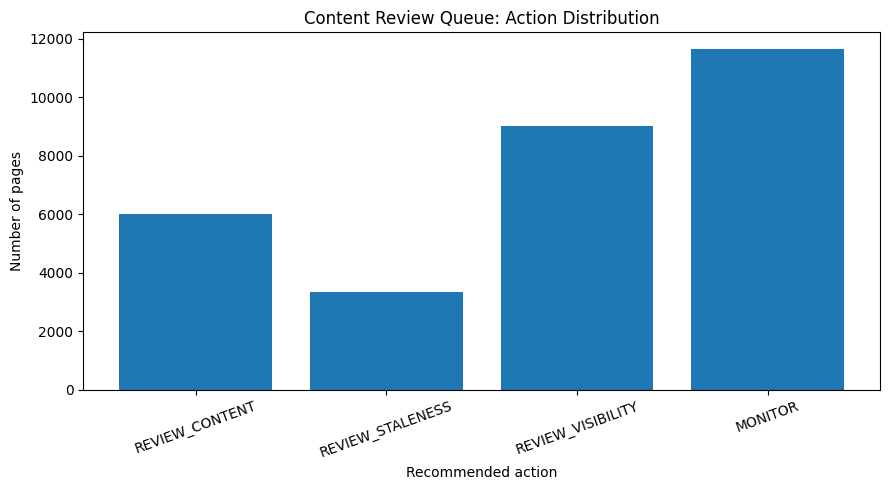

Saved paper artifacts:
- work/outputs/ml11_action_distribution.png
- work/outputs/ml11_action_summary.csv
- work/outputs/ml11_model_vs_baseline.csv

Action summary:
recommended_action  page_count  percentage
    REVIEW_CONTENT        5992       19.97
  REVIEW_STALENESS        3353       11.18
 REVIEW_VISIBILITY        9015       30.05
           MONITOR       11640       38.80

Model vs baseline:
                     model  precision_at_10  precision_at_20  average_precision  roc_auc
Week-4 rule-based baseline              0.4             0.40                NaN      NaN
       Logistic Regression              0.6             0.65              0.564   0.5726

PASS: paper artifacts created and verified.
Note: evaluation metrics are recorded from ML-08/ML-09, not recomputed here.


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path("work/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

# Reuse recommendation_summary if available; otherwise reconstruct it.
if "recommendation_summary" not in globals():
    if "df" not in globals():
        dataset_url = (
            "https://raw.githubusercontent.com/"
            "saibalaji2004/Flyrank-intern-repo/main/"
            "data/raw/content_refresh_anonymized.csv"
        )
        df = pd.read_csv(dataset_url)

    positive_impressions = df.loc[
        df["impressions_90d"] > 0, "impressions_90d"
    ]
    threshold = positive_impressions.median()

    stale = df["days_since_last_update"].ge(90).fillna(False)
    visible = df["impressions_90d"].ge(threshold).fillna(False)
    scores = 2 * stale.astype(int) + visible.astype(int)

    action_map = {
        3: "REVIEW_CONTENT",
        2: "REVIEW_STALENESS",
        1: "REVIEW_VISIBILITY",
        0: "MONITOR",
    }

    action_counts = scores.map(action_map).value_counts()
    action_order = [
        "REVIEW_CONTENT",
        "REVIEW_STALENESS",
        "REVIEW_VISIBILITY",
        "MONITOR",
    ]

    recommendation_summary = (
        action_counts.reindex(action_order, fill_value=0)
        .rename_axis("recommended_action")
        .reset_index(name="page_count")
    )
    recommendation_summary["percentage"] = (
        recommendation_summary["page_count"] / len(df) * 100
    ).round(2)

# Artifact 1: action-distribution chart.
fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(
    recommendation_summary["recommended_action"],
    recommendation_summary["page_count"],
)
ax.set_title("Content Review Queue: Action Distribution")
ax.set_xlabel("Recommended action")
ax.set_ylabel("Number of pages")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()

chart_path = output_dir / "ml11_action_distribution.png"
fig.savefig(chart_path, dpi=160, bbox_inches="tight")
plt.show()
plt.close(fig)

# Artifact 2: aggregate action summary.
summary_path = output_dir / "ml11_action_summary.csv"
recommendation_summary.to_csv(summary_path, index=False)

# Artifact 3: previously measured held-out model comparison.
evaluation_table = pd.DataFrame([
    {
        "model": "Week-4 rule-based baseline",
        "precision_at_10": 0.40,
        "precision_at_20": 0.40,
        "average_precision": np.nan,
        "roc_auc": np.nan,
    },
    {
        "model": "Logistic Regression",
        "precision_at_10": 0.60,
        "precision_at_20": 0.65,
        "average_precision": 0.564,
        "roc_auc": 0.5726,
    },
])

evaluation_path = output_dir / "ml11_model_vs_baseline.csv"
evaluation_table.to_csv(evaluation_path, index=False)

# Verify the aggregate counts and saved artifacts.
assert recommendation_summary["page_count"].sum() == 30000
assert chart_path.exists()
assert summary_path.exists()
assert evaluation_path.exists()

print("Saved paper artifacts:")
print("-", chart_path)
print("-", summary_path)
print("-", evaluation_path)

print("\nAction summary:")
print(recommendation_summary.to_string(index=False))

print("\nModel vs baseline:")
print(evaluation_table.to_string(index=False))

print("\nPASS: paper artifacts created and verified.")
print("Note: evaluation metrics are recorded from ML-08/ML-09, not recomputed here.")


In [ ]:

from google.colab import files

files.download("work/outputs/ml11_action_distribution.png")
files.download("work/outputs/ml11_action_summary.csv")
files.download("work/outputs/ml11_model_vs_baseline.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## ML-12: Five-Minute Capstone Demo

### 0:00–0:40 | Problem and research question
Explain the challenge: content teams need a practical way to decide which existing web pages to review first when search performance declines. Introduce the research question and the goal of explainable review prioritization.

### 0:40–1:20 | Dataset
Describe the anonymized FlyRank dataset: 30,000 content records and 44 original columns. Explain that the decline label is derived from `trend_direction` and represents an observed trend proxy, not confirmed refresh need.

### 1:20–2:10 | Methodology
Introduce the Week-4 rule-based baseline using freshness and 90-day impressions. Explain that Logistic Regression was evaluated with an 80/20 client-grouped split, keeping clients separate between training and testing.

### 2:10–3:10 | Results
Show the model-versus-baseline table. Logistic Regression achieved Precision@10 of 0.60 and Precision@20 of 0.65, compared with 0.40 for both metrics under the baseline. Mention the model's ROC-AUC of approximately 0.573 to communicate its limited overall discrimination.

### 3:10–4:10 | Action playbook
Show the action-distribution chart and explain the four actions: `REVIEW_CONTENT`, `REVIEW_STALENESS`, `REVIEW_VISIBILITY`, and `MONITOR`. Emphasize that the queue helps prioritize human review rather than automatically changing content.

### 4:10–5:00 | Limitations and conclusion
Discuss the proxy target, missing data, residual temporal leakage risk, and lack of future-period validation. Conclude that model-assisted prioritization is worth further evaluation, but the study does not prove that refreshing a page will improve search performance.

🚀 **Can machine learning help content teams decide which pages to review first?**

As part of my FlyRank ML Internship, I explored content refresh prioritization using an anonymized dataset of 30,000 content records.

I compared a transparent rule-based baseline with Logistic Regression using a client-grouped held-out evaluation.

📊 **Key results:**
- Precision@10: 0.60 for Logistic Regression vs. 0.40 for the baseline
- Precision@20: 0.65 vs. 0.40
- ROC-AUC: approximately 0.573, highlighting limited overall discrimination

The findings suggest that model-assisted ranking may help organize content-review work, but human judgment remains essential. The observed decline label is only a proxy, and the study does not prove that refreshing a page improves search rankings.

The project reinforced the importance of explainable methods, careful validation, and honest reporting of limitations.

#MachineLearning #SEO #DataScience #ContentStrategy #FlyRank

## ML-12: Employer-Facing Summary

Developed an explainable content-refresh prioritization workflow using an anonymized dataset of 30,000 content records, combining a rule-based baseline with Logistic Regression evaluated through a client-grouped held-out split. The model achieved Precision@10 of 0.60 and Precision@20 of 0.65, compared with 0.40 for both metrics under the baseline, while its ROC-AUC of approximately 0.573 indicated limited overall discrimination. The project demonstrates skills in data analysis, feature selection, leakage auditing, model evaluation, and decision-support design, while recognizing that human review and future-period validation are necessary before operational use.

## Self-check

Before you submit, confirm each line honestly:

- [ ] Every section above is filled — markdown thinking AND the code that backs it
- [ ] The notebook runs top to bottom with no errors (Runtime → Run all)
- [ ] No client names, URLs, or private queries anywhere
- [ ] My claims use careful words: observed, measured, directional, decision-support
- [ ] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.
- [ ] My deployed paper has **all 9 sections** — including the **Abstract** at the top and **Acknowledgments & data credit** (the https://flyrank.ai link) at the bottom.
- [ ] **ML-12 done in this notebook's closing cells:** 5-minute demo outline + a social-post cut + a 3-sentence employer-facing summary.
